# Exploratory visualizations — El Niño Over the Years
Six static views of the CESM2 AMIP data that lead to our question: **where does El Niño change the weather around the world?**

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data_folder = Path("../data")

nino = pd.read_csv(data_folder / "nino34.csv", parse_dates=["date"])
events = pd.read_csv(data_folder / "events.csv", parse_dates=["start", "end"])

with open(data_folder / "grid.json") as file:
    grid = json.load(file)
with open(data_folder / "hovmoller.json") as file:
    hov = json.load(file)

lats = np.array(grid["lat"])
lons = np.array(grid["lon"])
land = np.array(grid["land"]).reshape(len(lats), len(lons))

colors = {"El Niño": "#d6604d", "La Niña": "#4393c3"}


def load_map(variable, year, month):
    """Return a (lat, lon) anomaly grid for one month. variable is 'sst' or 'pr'."""
    with open(data_folder / variable / f"{year}.json") as file:
        d = json.load(file)
    values = np.array(d["months"][month - 1], dtype=float) * d["scale"]
    return values.reshape(len(lats), len(lons))

## Viz 1: ONI timeline
The Oceanic Niño Index (3-month running mean of the Niño 3.4 anomaly). Beyond ±0.5 °C for 5+ months counts as an event.

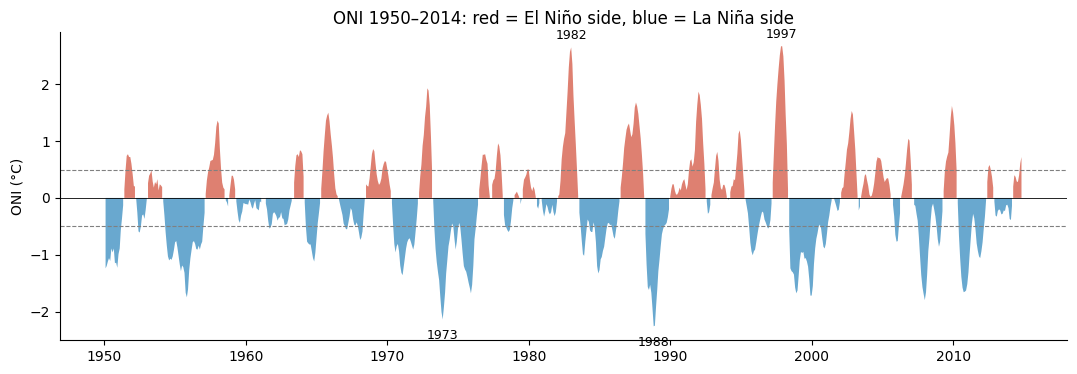

In [2]:
fig, ax = plt.subplots(figsize=(13, 4))
oni = nino["oni"]
ax.fill_between(nino["date"], oni, 0, where=oni > 0, color=colors["El Niño"], alpha=0.8, linewidth=0)
ax.fill_between(nino["date"], oni, 0, where=oni < 0, color=colors["La Niña"], alpha=0.8, linewidth=0)
for y in (0.5, -0.5):
    ax.axhline(y, color="gray", linestyle="--", linewidth=0.8)
ax.axhline(0, color="black", linewidth=0.6)

for _, e in events.loc[events["peak"].abs() > 2].iterrows():
    peak_date = nino.loc[nino["date"].between(e["start"], e["end"]), :].set_index("date")["oni"].abs().idxmax()
    ax.annotate(e["start"].year, (peak_date, e["peak"]), textcoords="offset points",
                xytext=(0, 6 if e["peak"] > 0 else -14), ha="center", fontsize=9)

ax.set_title("ONI 1950–2014: red = El Niño side, blue = La Niña side")
ax.set_ylabel("ONI (°C)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Viz 2: Event strength
Peak ONI of each of the 34 events.

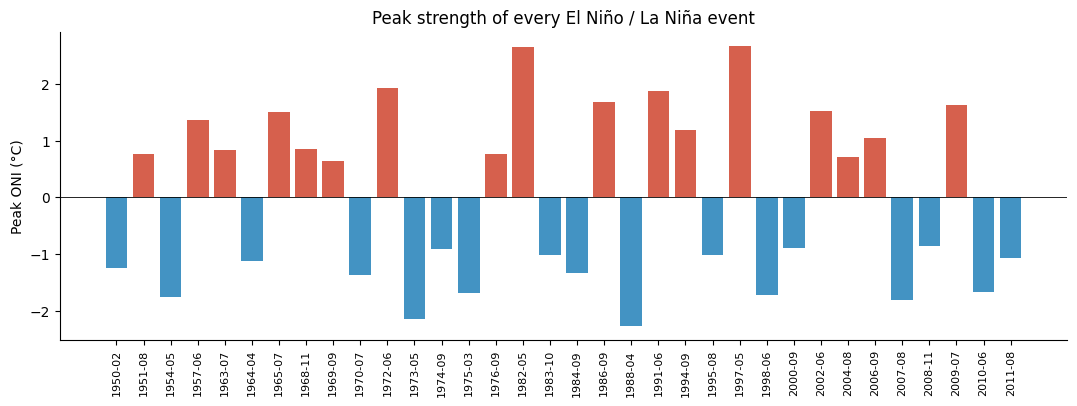

In [3]:
fig, ax = plt.subplots(figsize=(13, 4))
labels = events["start"].dt.strftime("%Y-%m")
ax.bar(labels, events["peak"], color=events["phase"].map(colors))
ax.axhline(0, color="black", linewidth=0.6)
ax.set_title("Peak strength of every El Niño / La Niña event")
ax.set_ylabel("Peak ONI (°C)")
ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Viz 3: Duration vs. strength
Do stronger events last longer? Do La Niñas last longer than El Niños?

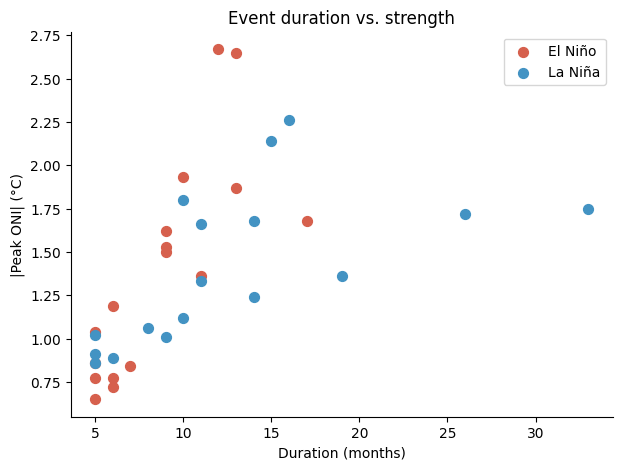

,count,mean,max
phase,,,
El Niño,17.0,8.705882,17.0
La Niña,17.0,12.764706,33.0


In [4]:
events["months"] = (events["end"].dt.year - events["start"].dt.year) * 12 + \
                   (events["end"].dt.month - events["start"].dt.month) + 1

fig, ax = plt.subplots(figsize=(7, 5))
for phase, group in events.groupby("phase"):
    ax.scatter(group["months"], group["peak"].abs(), color=colors[phase], label=phase, s=50)
ax.set_xlabel("Duration (months)")
ax.set_ylabel("|Peak ONI| (°C)")
ax.set_title("Event duration vs. strength")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

events.groupby("phase")["months"].describe()[["count", "mean", "max"]]

## Viz 4: Hovmöller diagram
Equatorial Pacific temperature anomaly by longitude (x) and time (y). Warm water spreading east shows up as red streaks.

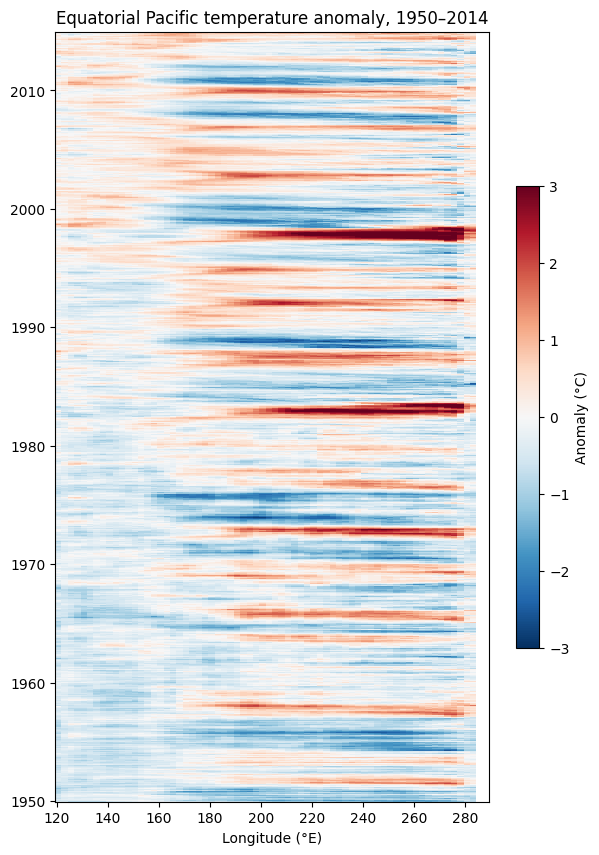

In [5]:
hov_values = np.array(hov["values"], dtype=float) * hov["scale"]
hov_dates = pd.to_datetime(hov["dates"])

fig, ax = plt.subplots(figsize=(7, 10))
mesh = ax.pcolormesh(hov["lon"], hov_dates, hov_values, cmap="RdBu_r", vmin=-3, vmax=3, shading="auto")
ax.set_xlabel("Longitude (°E)")
ax.set_title("Equatorial Pacific temperature anomaly, 1950–2014")
fig.colorbar(mesh, ax=ax, label="Anomaly (°C)", shrink=0.6)
plt.show()

## Viz 5: Temperature anomaly maps
Peak of the strongest El Niño (Dec 1997) vs. the strongest La Niña (Dec 1988).

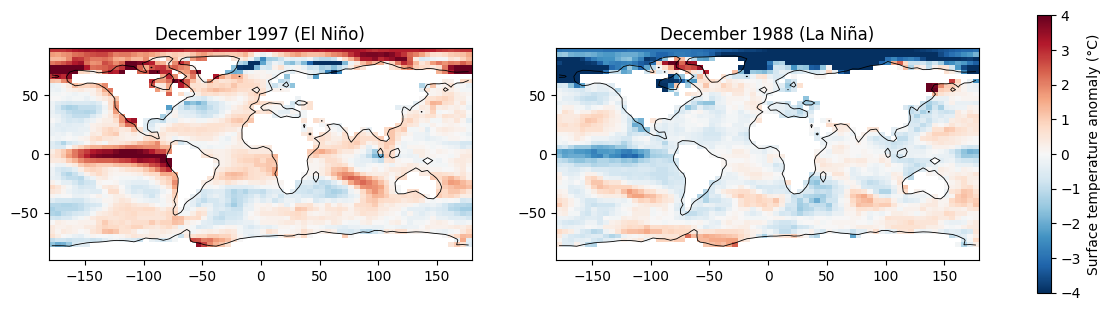

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (year, title) in zip(axes, [(1997, "December 1997 (El Niño)"), (1988, "December 1988 (La Niña)")]):
    mesh = ax.pcolormesh(lons, lats, load_map("sst", year, 12), cmap="RdBu_r", vmin=-4, vmax=4, shading="auto")
    ax.contour(lons, lats, land, levels=[0.5], colors="black", linewidths=0.6)
    ax.set_title(title)
    ax.set_aspect("equal")
fig.colorbar(mesh, ax=axes, label="Surface temperature anomaly (°C)", shrink=0.8)
plt.show()

## Viz 6: Rainfall anomaly maps
Same months: how the model's rainfall responds.

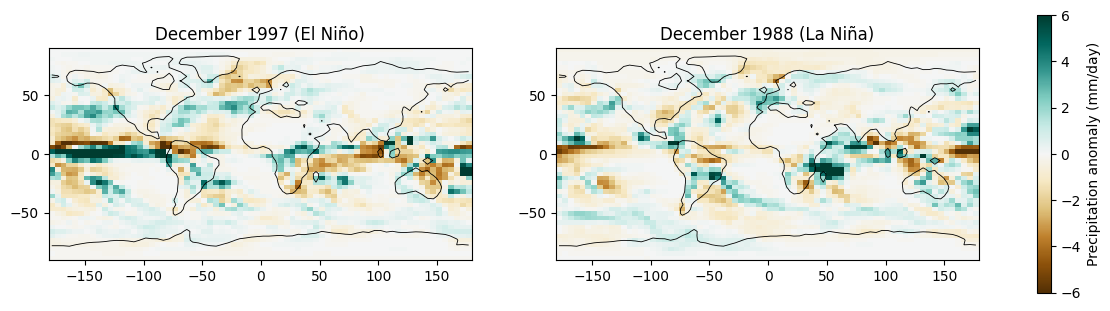

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (year, title) in zip(axes, [(1997, "December 1997 (El Niño)"), (1988, "December 1988 (La Niña)")]):
    mesh = ax.pcolormesh(lons, lats, load_map("pr", year, 12), cmap="BrBG", vmin=-6, vmax=6, shading="auto")
    ax.contour(lons, lats, land, levels=[0.5], colors="black", linewidths=0.6)
    ax.set_title(title)
    ax.set_aspect("equal")
fig.colorbar(mesh, ax=axes, label="Precipitation anomaly (mm/day)", shrink=0.8)
plt.show()

## Takeaway → final interactive design
ONI timeline as a brush/slider on top; selecting a month updates the temperature and rainfall maps below (toggle), with tooltips per grid cell.